# Dong 2020 Prostate — 03 Signatures
Score the three embryonic modules (Gast, pSom, Crest) with the **union control pool** and map them on the manifold. Signature UMAPs show **raw** per-cell scores (smoothing is used only to *read* geography/correlations, never as a deliverable).

**Gate 2 = GO (non-branching).** Gast and pSom **co-vary** and spatially **overlap** (they do not split into a pSom-leaning vs a Gast-leaning arm), and Crest is an **inverse terminal gradient** (low where Gast/pSom are high, high at the late end). Per the task definition, the non-branching case PASSES; there is no bifurcation, so Gate 3 = NA and the branching-only correlation/modules steps are not produced.

In [1]:
import os, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
pth      = os.path.join('..', '..', '..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Prostate', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Prostate', name)
pth_cb   = os.path.join(pth_out, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad')); adata

AnnData object with n_obs × n_vars = 8281 × 15672
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', 'compartment', 'GSE162534', 'GSE229103', 'rRNAModifications', 'Gast', 'pSom', 'Crest', 'AR_luminal', 'NE_program', 'lineage', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'celltype_colors', 'compartment_colors', 'diffmap_evals', 'graph', 'leiden', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_diffmap', 'X_pca', 'X_pca_harmony', 'X_umap', 'harm_th0', 'harm_th10', 'harm_th2', 'harm_th5'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Score modules with the union control pool (basename keys, protocol style)

In [4]:
feat_fn  = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src  = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn): get_feat(fn) for fn in feat_fn}
g_ref = feat_dict['union'].loc[feat_dict['union'].isin(adata.var_names)].copy()
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src.loc[df_src.isin(adata.var_names)].copy()
        sc.tl.score_genes(adata, gene_list=g, score_name=src, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
        print(src, g.size, g_ref.size)

GSE162534 71 217
GSE229103 83 217
rRNAModifications 99 217


### Module geography confirms the non-branching pattern
Gast<->pSom **positive** (overlap, not competing arms); both **oppose** Crest; along pseudotime Gast/pSom fall and Crest rises (inverse terminal gradient).

In [5]:
for x,y in [('GSE162534','GSE229103'),('GSE162534','rRNAModifications'),('GSE229103','rRNAModifications')]:
    print(f'{x} <-> {y}:  r = {pearsonr(adata.obs[x], adata.obs[y])[0]:+.2f}')
print()
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    print(f'{lab:5s} vs pseudotime  rho = {spearmanr(adata.obs.t, adata.obs[src])[0]:+.2f}')

GSE162534 <-> GSE229103:  r = +0.47
GSE162534 <-> rRNAModifications:  r = -0.38
GSE229103 <-> rRNAModifications:  r = -0.40

Gast  vs pseudotime  rho = -0.17
pSom  vs pseudotime  rho = -0.41
Crest vs pseudotime  rho = +0.39


### Gastrulation signature (raw scores)

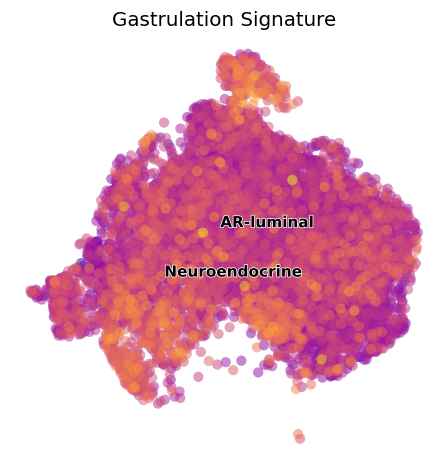

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='GSE162534', cmap='plasma', alpha=.5, size=180, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Gastrulation Signature', size=13)
fn = os.path.join(pth_out, 'Gast_signature.pdf'); plt.savefig(fn, bbox_inches='tight'); plt.show()

In [7]:
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0); cb.set_label('Gast\nSignature')
cb.solids.set_alpha(1); plt.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches='tight'); plt.close()

### Somitogenesis (pSom) signature (raw scores)

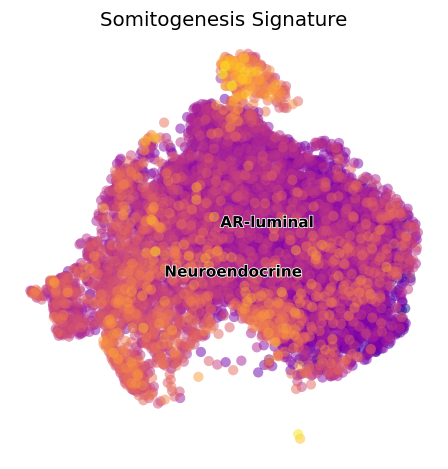

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='GSE229103', cmap='plasma', alpha=.5, size=180, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Somitogenesis Signature', size=13)
fn = os.path.join(pth_out, 'pSom_signature.pdf'); plt.savefig(fn, bbox_inches='tight'); plt.show()

In [9]:
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0); cb.set_label('pSom\nSignature')
cb.solids.set_alpha(1); plt.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches='tight'); plt.close()

### Neural crest signature (raw scores) — inverse terminal gradient

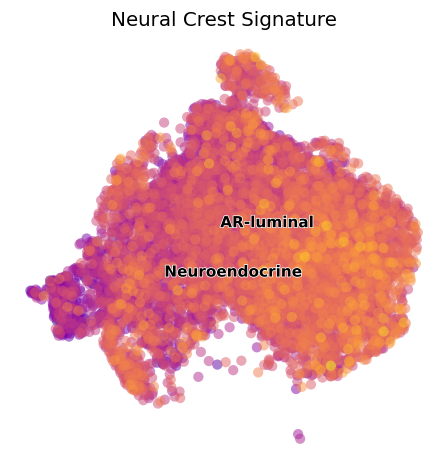

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='rRNAModifications', cmap='plasma', alpha=.5, size=180, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Neural Crest Signature', size=13)
fn = os.path.join(pth_out, 'Crest_signature.pdf'); plt.savefig(fn, bbox_inches='tight'); plt.show()

In [11]:
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0); cb.set_label('Crest\nSignature')
cb.solids.set_alpha(1); plt.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches='tight'); plt.close()

In [12]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('saved', os.path.join(pth_in, 'signatures.h5ad'))

saved ../../../../../../data/cancer/vertebrate/CCCA/Claude/Prostate/Dong2020_Prostate-5/signatures.h5ad
